In [ ]:
import numpy as np
import pandas as pd
# Kaggle 경로 자동 탐색 (로컬이면 ../data)
import os, glob
cands = glob.glob('/kaggle/input/**/train.csv', recursive=True)
DATA = os.path.dirname(cands[0]) if cands else '../data'
print(DATA)

In [2]:
#1. 라이브러리 불러오기 & 데이터 불러오기 
import pandas as pd,numpy as np
import matplotlib.pyplot as plt, seaborn as sb 
train = pd.read_csv(f'{DATA}/train.csv')
test = pd.read_csv(f'{DATA}/test.csv')

train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [3]:
#2 데이터 구조 파악  
#2-1 Feature를 수치형, 명목형으로 나누기 (ID, Target 제외)
features = train.drop(columns=['Id', 'SalePrice'])

num_cols = features.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = features.select_dtypes(include=['object']).columns.tolist()

#MSSubClass, MoSold, YrSold은 수치형이지만 명목형으로 취급해야 함
# MSSubClass(건물 유형), MoSold(판매 월), YrSold(판매 연도)는 숫자지만 명목형
to_cat = ['MSSubClass', 'MoSold', 'YrSold']
num_cols = [c for c in num_cols if c not in to_cat]
cat_cols = cat_cols + [c for c in to_cat if c not in cat_cols]

for c in to_cat:
    train[c] = train[c].astype(str)
    test[c] = test[c].astype(str)

print(len(num_cols), "개의 수치형 Feature")
print(len(cat_cols), "개의 명목형 Feature")


33 개의 수치형 Feature
46 개의 명목형 Feature


In [4]:
# 2-2a SalesPrice의 분포 확인
train['SalePrice'].describe()


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Text(0, 0.5, 'Frequency')

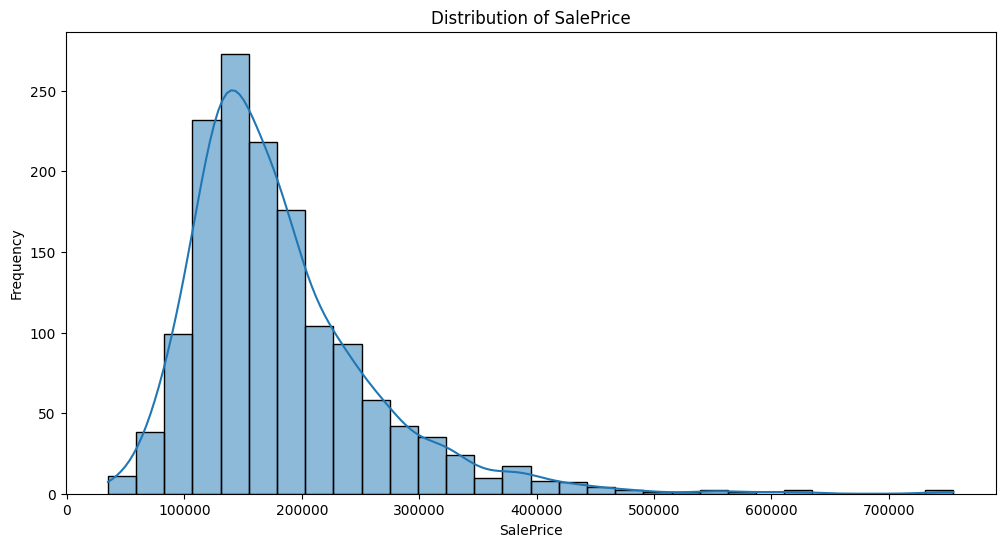

In [5]:
# 2-2b SalesPrice의 분포 그래프
plt.figure(figsize=(12, 6))
sb.histplot(train['SalePrice'], bins=30, kde=True)
plt.title('Distribution of SalePrice')
plt.xlabel('SalePrice')
plt.ylabel('Frequency')

# right-skewed (mean value approx. 180000 > median value 163000)
# outliers making mean value higher
# median value가 mean보다 보통 집값으로 말하기 적합할듯

In [6]:
#2-2c 왜도(Skewness)와 첨도(Kurtosis) 확인
print('왜도(Skewness):', train['SalePrice'].skew())   # 1.88 = 오른쪽으로 너무 많이 치우침
print('첨도(Kurtosis):', train['SalePrice'].kurt())   # 6.54 = 꼬리의 두께 극단적인 값의 빈도수가 높음 

# outliers의 값의 영향을 줄이기 위해서 로그변환 필요해보임

왜도(Skewness): 1.8828757597682129
첨도(Kurtosis): 6.536281860064529


In [7]:
#2-3a 수치형 Feature 분석

train[num_cols].describe().T

#결측치 존재:LotFrontage,MasVnrArea,GarageYrBlt  
#outlier 존재 : LotFrontage, LotArea, MasVnrArea, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, GrLivArea, GarageArea

,count,mean,std,min,25%,50%,75%,max
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0
BsmtUnfSF,1460.0,567.240411,441.866955,0.0,223.00,477.5,808.00,2336.0


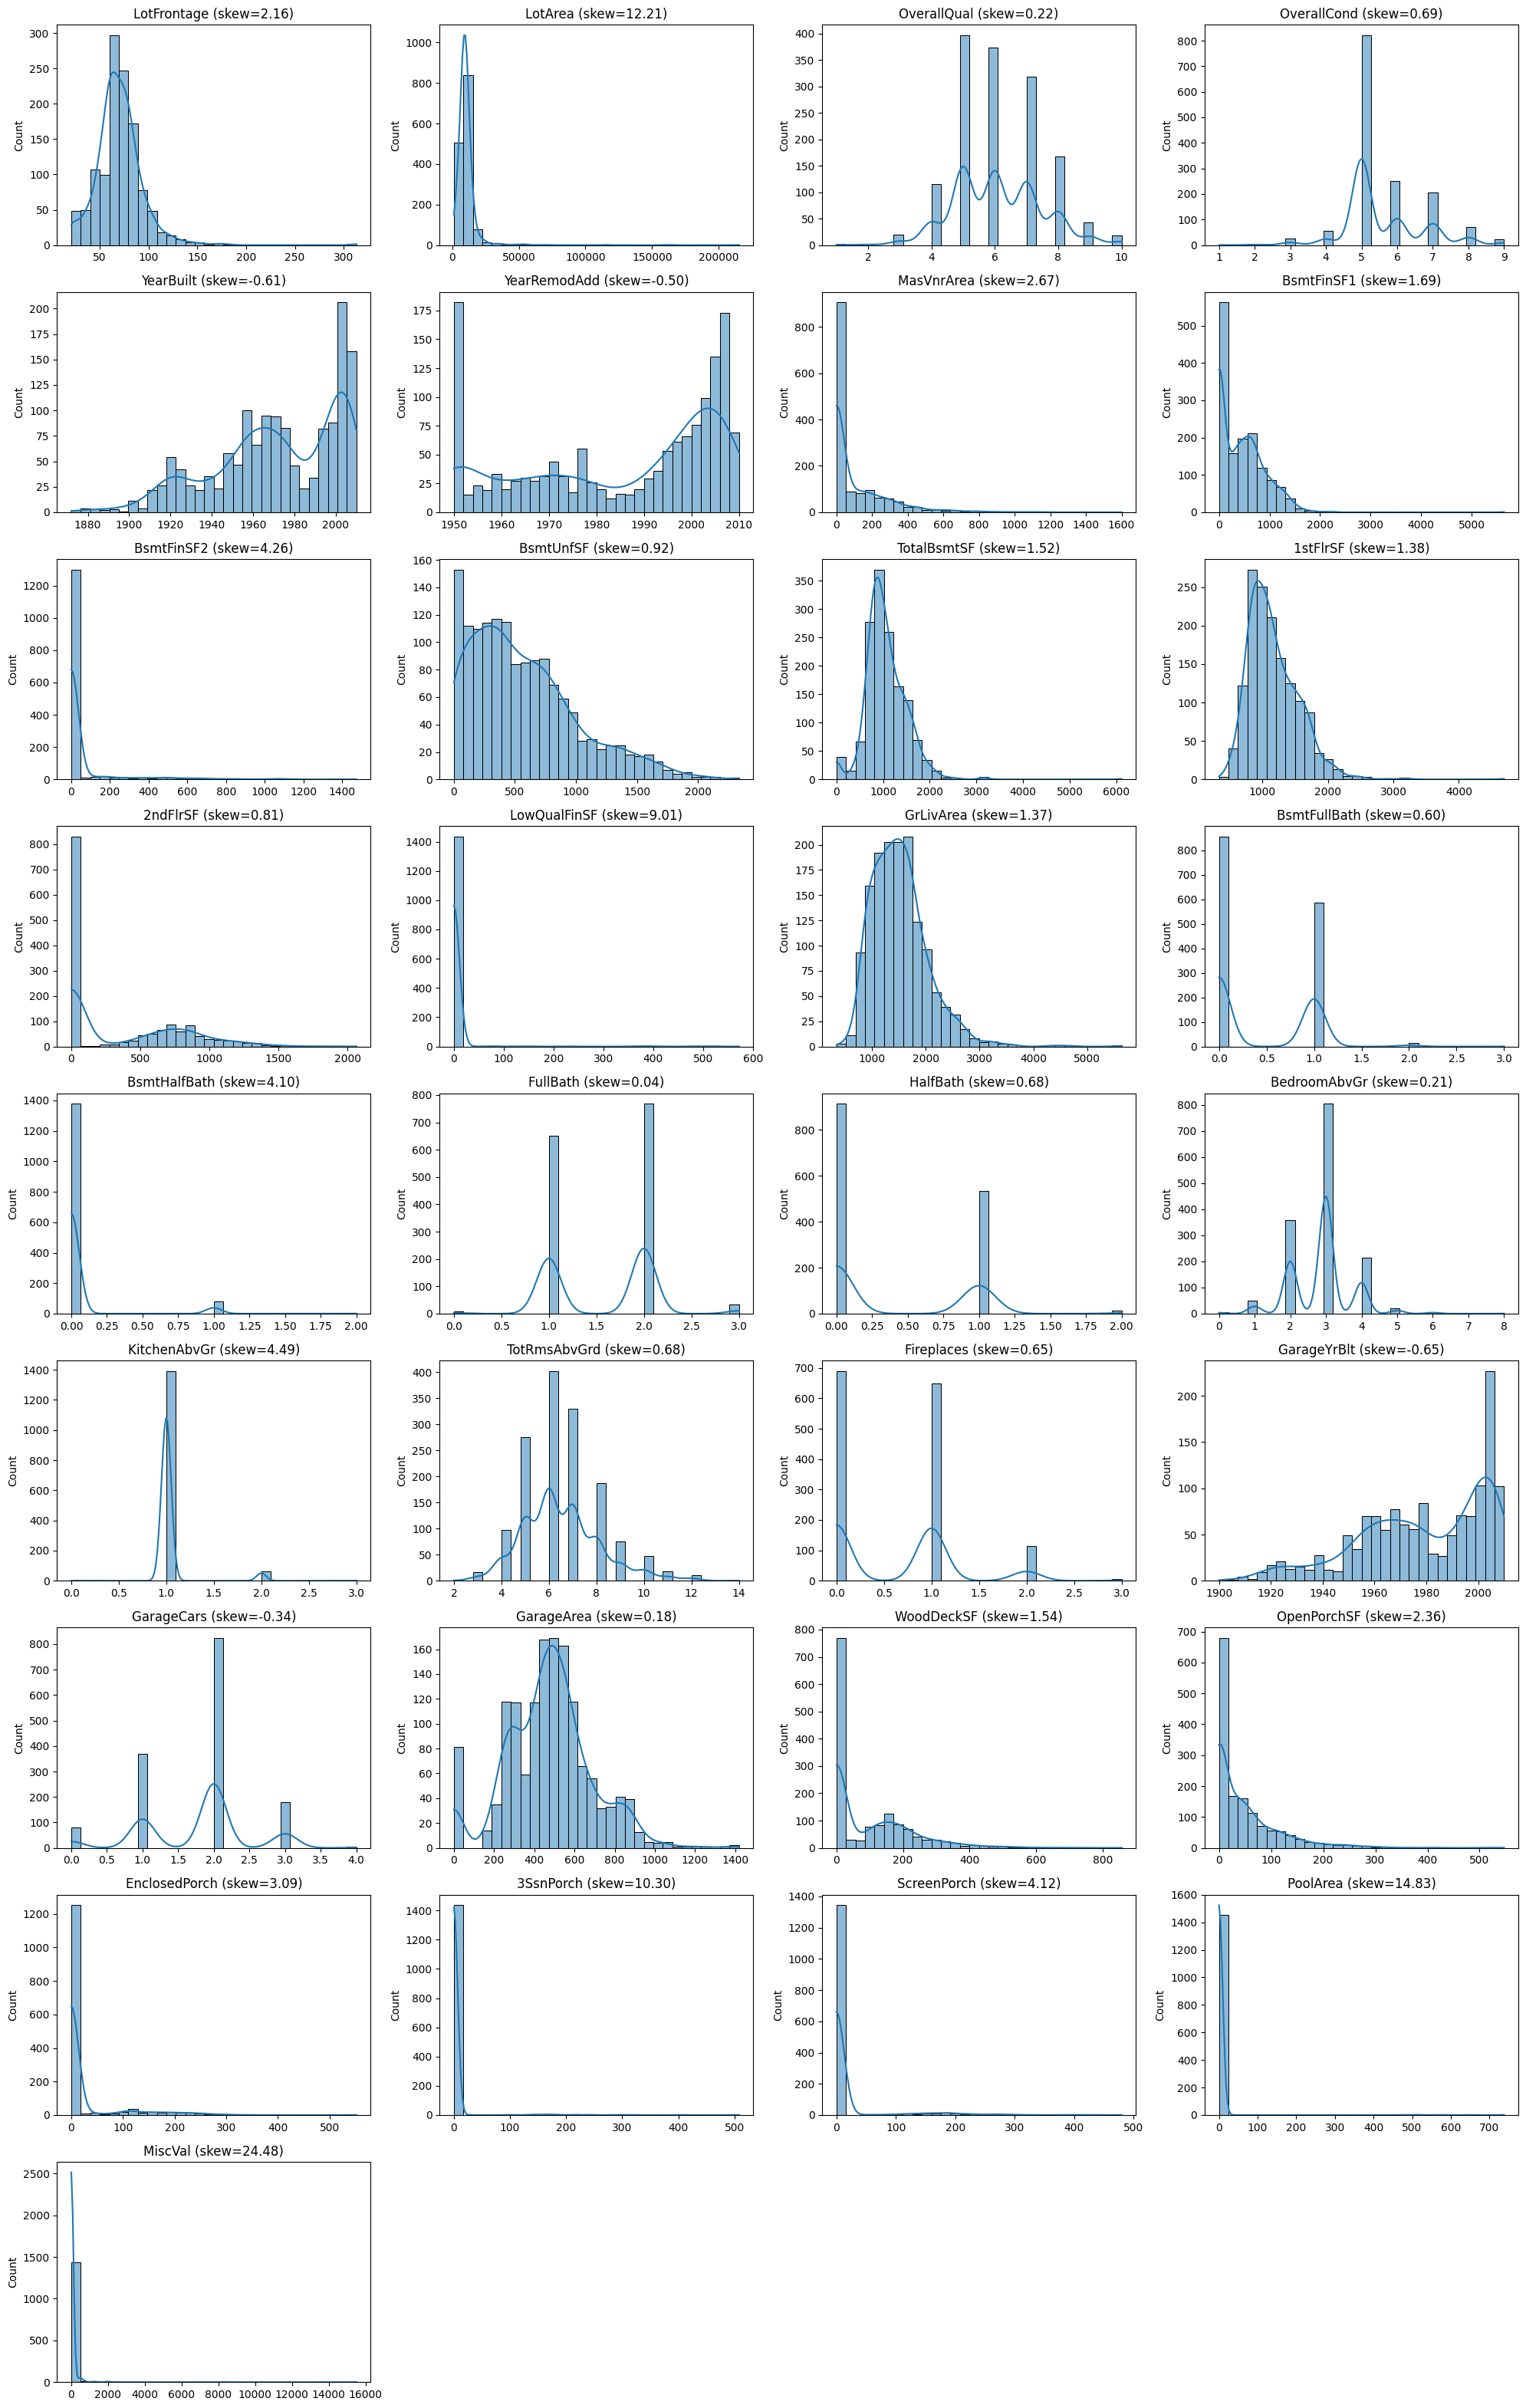

In [8]:
#2-3b 수치형 Feature 분포 그래프

n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))   # 33개 → 9줄

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()   # 2차원 격자를 1차원으로 펴서 하나씩 접근

for i, col in enumerate(num_cols):
    sb.histplot(train[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'{col} (skew={train[col].skew():.2f})')
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):   # 남는 빈 칸 지우기
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# 로그 변환: LotArea, LotFrontage, BsmtFinSF1, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, GrLivArea
# 이진화(대부분 0): PoolArea, MiscVal, 3SsnPorch, LowQualFinSF, BsmtFinSF2, ScreenPorch, EnclosedPorch
# 이진 + 원래 값 유지: 2ndFlrSF, MasVnrArea, WoodDeckSF, OpenPorchSF, TotalBsmtSF(0=없음), GarageArea(0=없음)
# 개수·등급형(KDE 무시): FullBath, HalfBath, Bedroom, Fireplaces, GarageCars, TotRms, OverallQual/Cond
# 정보 적음: KitchenAbvGr(거의 1), OverallCond(대부분 5)
# 주의: YearRemodAdd 1950은 1950년 이전 기록이 잘린 값

In [9]:
#2-4a 명목형 Feature 분석
train[cat_cols].describe().T

# 결측치 존재: Alley, MasVnrType, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, Electrical, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PoolQC, Fence, MiscFeature

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


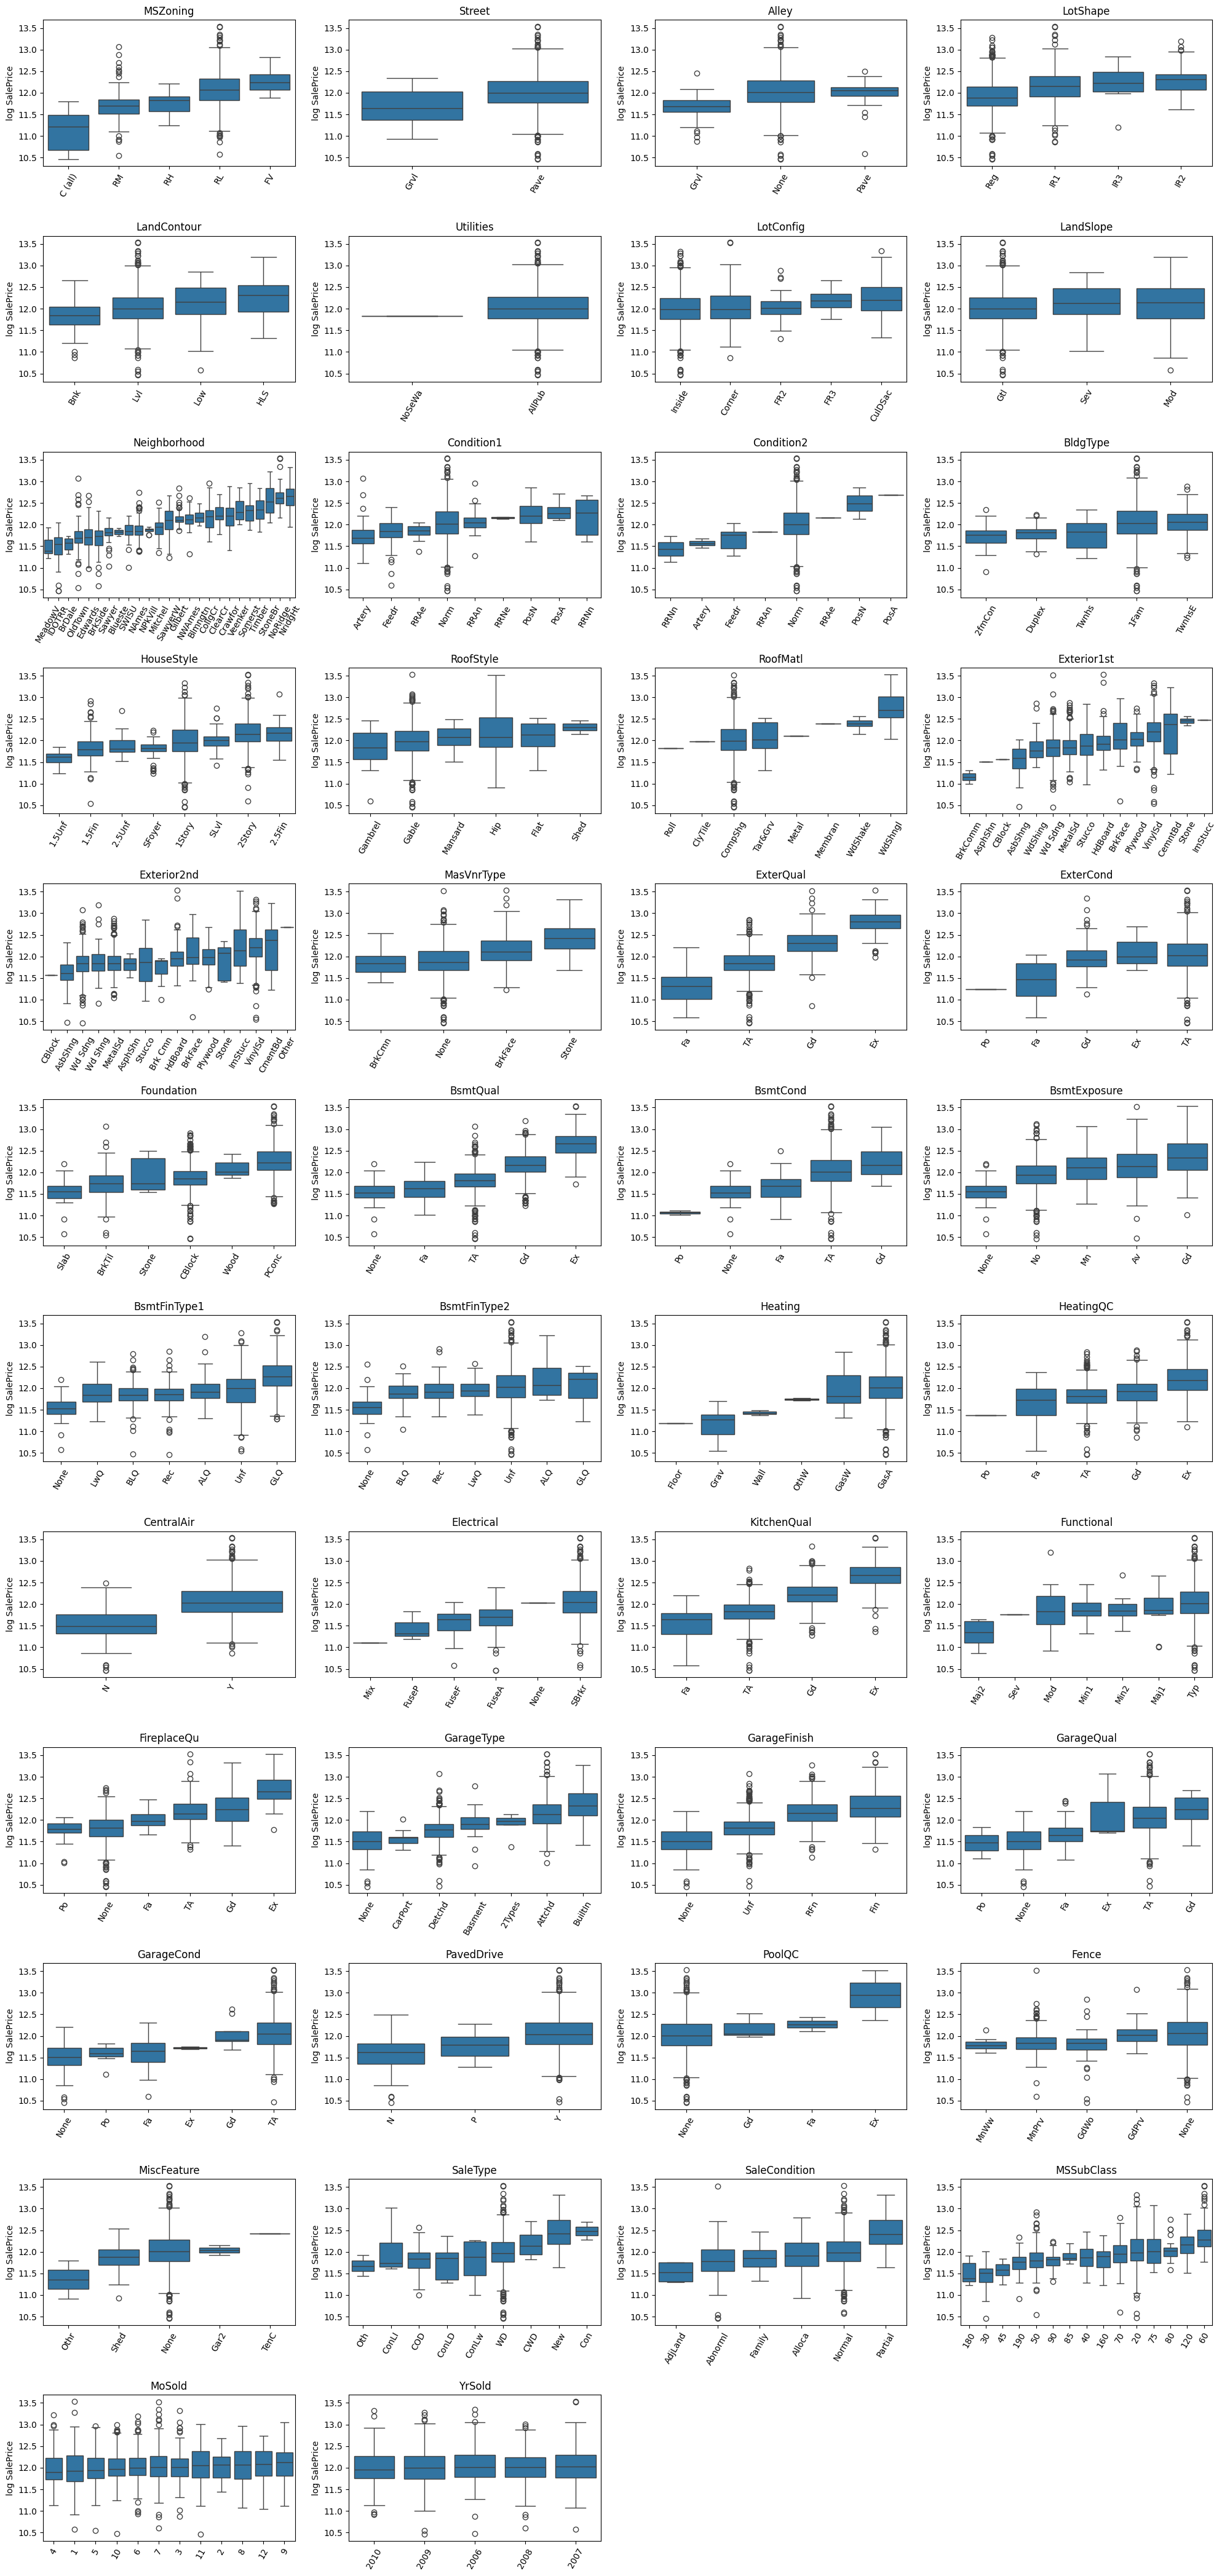

In [10]:
#2-4b 명목형 Feature 분포 그래프

n_cols = 4
n_rows = int(np.ceil(len(cat_cols) / n_cols)) 

cat_df = train[cat_cols].fillna('None')
log_price = np.log1p(train['SalePrice'])

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = log_price.groupby(cat_df[col]).median().sort_values().index   # 가격 순 정렬
    sb.boxplot(x=cat_df[col], y=log_price, order=order, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('log SalePrice')
    axes[i].tick_params(axis='x', rotation=60)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# 가격 관련 강함: ExterQual, KitchenQual, BsmtQual, FireplaceQu, HeatingQC, GarageFinish,
#               Neighborhood, MSZoning, Foundation, GarageType, MasVnrType, CentralAir
# 순서형 인코딩 적합(계단 깔끔): ExterQual, KitchenQual, BsmtQual, FireplaceQu, HeatingQC, GarageFinish, BsmtExposure
# 순서가 어긋남 → 명목형 유지: ExterCond, BsmtFinType1
# 가격 관련 약함: LotConfig, LandSlope, BldgType, RoofStyle
# 희귀 범주 많음(박스 신뢰 X): Utilities, Condition2, RoofMatl, Heating → 묶거나 제거
# None(시설 없음)은 대부분 가장 낮음 → 결측을 'None' 범주로 채운 게 맞음

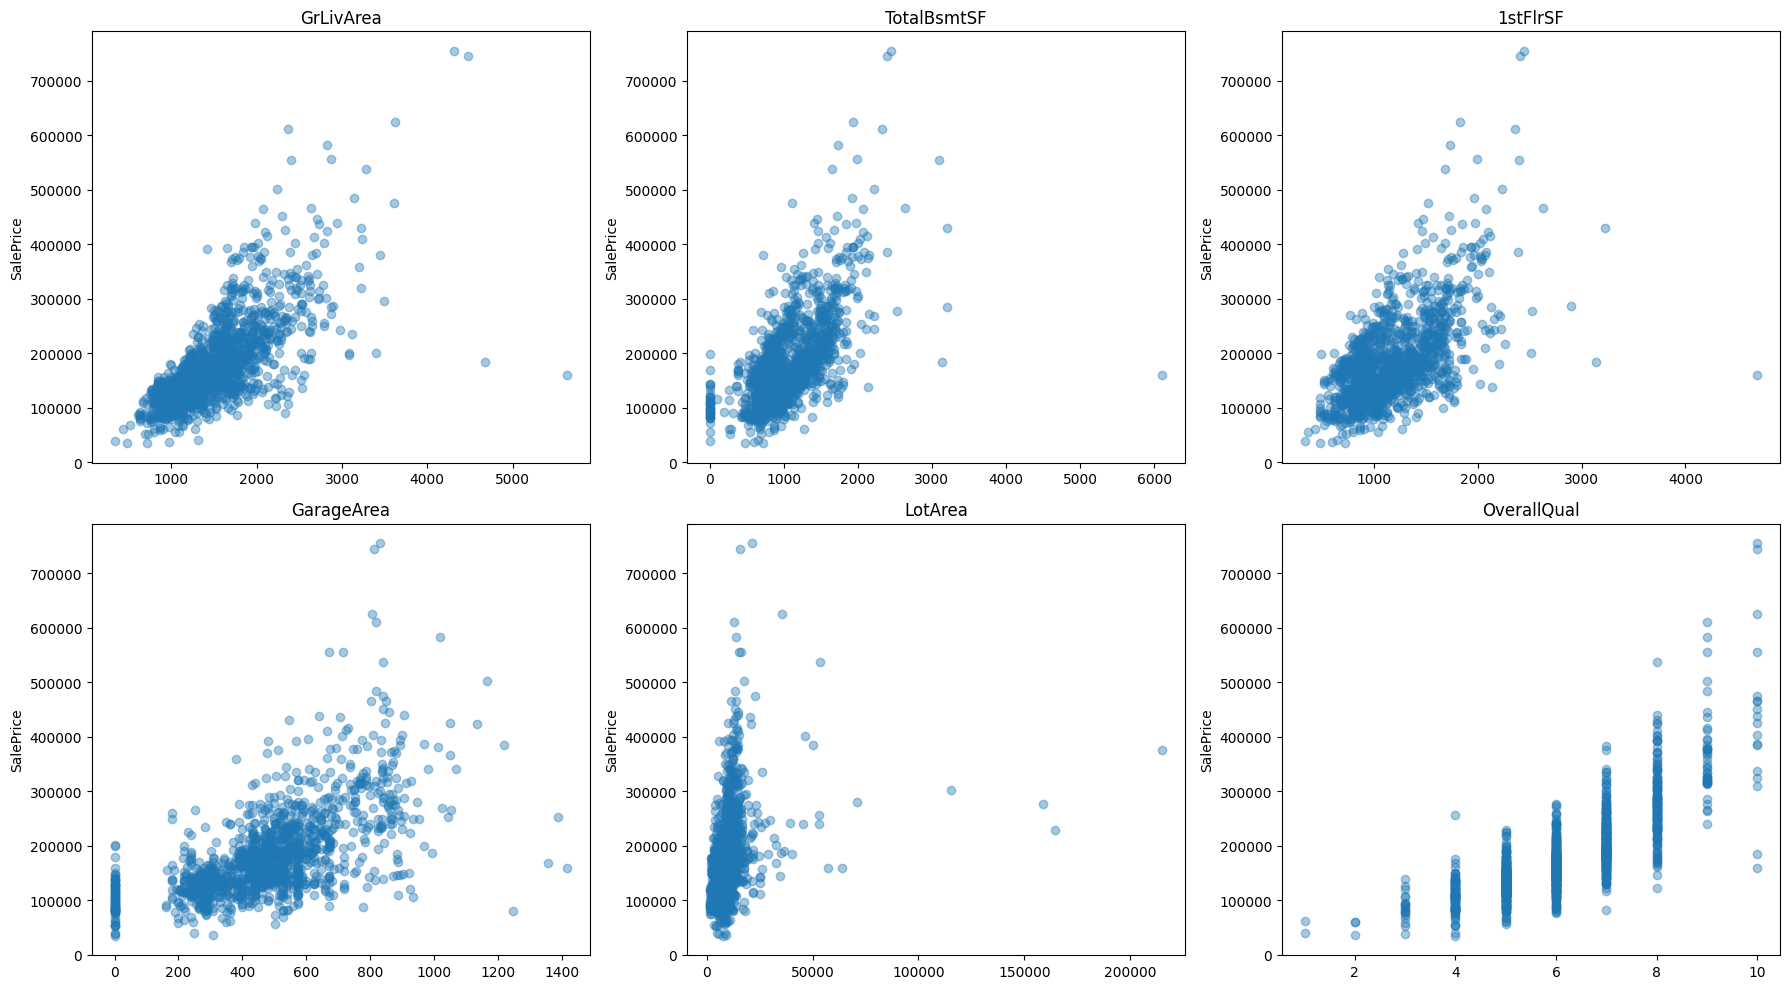

In [11]:
#2-5 Outlier 확인 
cols = ['GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'GarageArea', 'LotArea', 'OverallQual']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].scatter(train[col], train['SalePrice'], alpha=0.4)
    axes[i].set_title(col)
    axes[i].set_ylabel('SalePrice')

plt.tight_layout()
plt.show()

# 이상치 제거: Id 524, 1299
#  - GrLivArea 대비 가격이 비정상적으로 낮음 (오른쪽 아래)
#  - Id 1299는 TotalBsmtSF, 1stFlrSF에서도 동떨어진 점
#  - 둘 다 OverallQual 10인데 가격은 하위권, SaleCondition = Partial
# 유지: Id 692, 1183 (크고 비싼 집, 추세를 따름)
# LotArea 극단값은 가격이 정상 → 제거 X, 로그 변환

In [12]:
#3 전처리  

#3-1 Salesprice 로그변환 + 이상치 제거 + train/test 합치기

# 1. 이상치 제거
train = train[~train['Id'].isin([524, 1299])].reset_index(drop=True)

# 타깃은 로그 변환해서 따로 보관, 제출용 test Id도 보관 
y = np.log1p(train['SalePrice'])
test_id = test['Id']

# 2. train과 test 합치기
n_train = len(train)
all_data = pd.concat([train.drop(columns=['Id', 'SalePrice']),
                      test.drop(columns=['Id'])]).reset_index(drop=True)

print(all_data.shape)   # (2917, 79)

# 합친 데이터의 결측 현황
na = all_data.isnull().sum()
na[na > 0].sort_values(ascending=False)

(2917, 79)


PoolQC          2908
MiscFeature     2812
Alley           2719
Fence           2346
MasVnrType      1766
FireplaceQu     1420
LotFrontage      486
GarageQual       159
GarageYrBlt      159
GarageCond       159
GarageFinish     159
GarageType       157
BsmtExposure      82
BsmtCond          82
BsmtQual          81
BsmtFinType2      80
BsmtFinType1      79
MasVnrArea        23
MSZoning           4
BsmtFullBath       2
Functional         2
BsmtHalfBath       2
Utilities          2
BsmtFinSF1         1
Exterior2nd        1
Exterior1st        1
Electrical         1
TotalBsmtSF        1
BsmtUnfSF          1
BsmtFinSF2         1
KitchenQual        1
GarageArea         1
GarageCars         1
SaleType           1
dtype: int64

In [13]:
#3-2 결측치 처리
# (1) NA = "시설 없음"인 명목형 → 'None'
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
for c in none_cols:
    all_data[c] = all_data[c].fillna('None')

# (2) 시설이 없으면 면적·개수도 0인 수치형 → 0
zero_cols = ['GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
             'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for c in zero_cols:
    all_data[c] = all_data[c].fillna(0)

# (3) 값을 추정해야 하는 컬럼
# 차고 연도: 차고가 없으면 집 건축 연도로 채움 (0으로 채우면 '0년에 지은 차고'가 됨)
all_data['GarageYrBlt'] = all_data['GarageYrBlt'].fillna(all_data['YearBuilt'])

# 도로 접면 길이: 같은 동네 집들은 대지 모양이 비슷하므로 동네별 중앙값으로 채움
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'] \
                                  .transform(lambda s: s.fillna(s.median()))

# (4) 결측이 1~4개뿐인 컬럼 → 가장 흔한 값
all_data['Functional'] = all_data['Functional'].fillna('Typ')   # 설명서상 기본값이 Typ

mode_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd',
             'SaleType', 'Utilities']
for c in mode_cols:
    all_data[c] = all_data[c].fillna(all_data[:n_train][c].mode()[0])

print('남은 결측:', all_data.isnull().sum().sum())   # 0이 나와야 함

남은 결측: 0


In [14]:
#3-3 Feature 변환 

#3-3a 불필요한 컬럼 제거+ 타입정리

# 거의 전부 AllPub이라 정보 없음
all_data = all_data.drop(columns=['Utilities'])

# 숫자지만 명목형인 컬럼 (앞에서 train만 바꿨을 수 있으니 all_data에 다시 적용)
for c in ['MSSubClass', 'MoSold', 'YrSold']:
    all_data[c] = all_data[c].astype(str)

In [15]:
#3-3b 순서형 인코딩

qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for c in ['ExterQual', 'KitchenQual', 'BsmtQual', 'FireplaceQu', 'HeatingQC']:
    all_data[c] = all_data[c].map(qual_map)

all_data['GarageFinish'] = all_data['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})
all_data['BsmtExposure'] = all_data['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4})

In [16]:
#3-3c 파생 변수 만들기 

# 총면적, 총 욕실 수
all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']
all_data['TotalBath'] = (all_data['FullBath'] + 0.5 * all_data['HalfBath']
                         + all_data['BsmtFullBath'] + 0.5 * all_data['BsmtHalfBath'])

# 건물 나이, 리모델링 후 경과 연수 (음수는 0으로)
all_data['HouseAge'] = (all_data['YrSold'].astype(int) - all_data['YearBuilt']).clip(lower=0)
all_data['RemodAge'] = (all_data['YrSold'].astype(int) - all_data['YearRemodAdd']).clip(lower=0)

# 현관·데크 총면적
all_data['TotalPorchSF'] = (all_data['OpenPorchSF'] + all_data['EnclosedPorch']
                            + all_data['3SsnPorch'] + all_data['ScreenPorch'] + all_data['WoodDeckSF'])

# 시설 유무 이진 변수
for c in ['PoolArea', '2ndFlrSF', 'GarageArea', 'TotalBsmtSF', 'MasVnrArea', 'Fireplaces']:
    all_data['Has' + c] = (all_data[c] > 0).astype(int)

In [17]:
#3-3c-1 이진화: 대부분 0인 컬럼 → 유무만 남기고 원래 값은 제거
binary_only = ['PoolArea', 'MiscVal', '3SsnPorch', 'LowQualFinSF',
               'BsmtFinSF2', 'ScreenPorch', 'EnclosedPorch']
for c in binary_only:
    all_data['Has' + c] = (all_data[c] > 0).astype(int)
all_data = all_data.drop(columns=binary_only)

# 이진 + 원래 값 유지
for c in ['WoodDeckSF', 'OpenPorchSF']:
    all_data['Has' + c] = (all_data[c] > 0).astype(int)

In [18]:
#3-3c-2 희귀 범주 묶기: train에서 10채 미만인 범주는 'Other'로
for c in ['Condition2', 'RoofMatl', 'Heating']:
    counts = all_data[:n_train][c].value_counts()
    keep = counts[counts >= 10].index
    all_data[c] = all_data[c].where(all_data[c].isin(keep), 'Other')
    print(c, all_data[c].value_counts().to_dict())

Condition2 {'Norm': 2888, 'Other': 29}
RoofMatl {'CompShg': 2875, 'Tar&Grv': 23, 'Other': 19}
Heating {'GasA': 2872, 'GasW': 27, 'Other': 18}


In [19]:
#3-3d 로그 변환

log_cols = ['LotArea', 'LotFrontage', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF',
            '1stFlrSF', 'GrLivArea', 'TotalSF', 'MasVnrArea', 'TotalPorchSF']
for c in log_cols:
    all_data[c] = np.log1p(all_data[c])

In [20]:
#3-3e 원-핫 인코딩 + 다시 나누기 

all_data = pd.get_dummies(all_data).astype(float)
print(all_data.shape)   # (2917, 314)

X = all_data[:n_train]
X_test = all_data[n_train:]
print(X.shape, X_test.shape)   # (1458, 314) (1459, 314)

(2917, 302)
(1458, 302) (1459, 302)


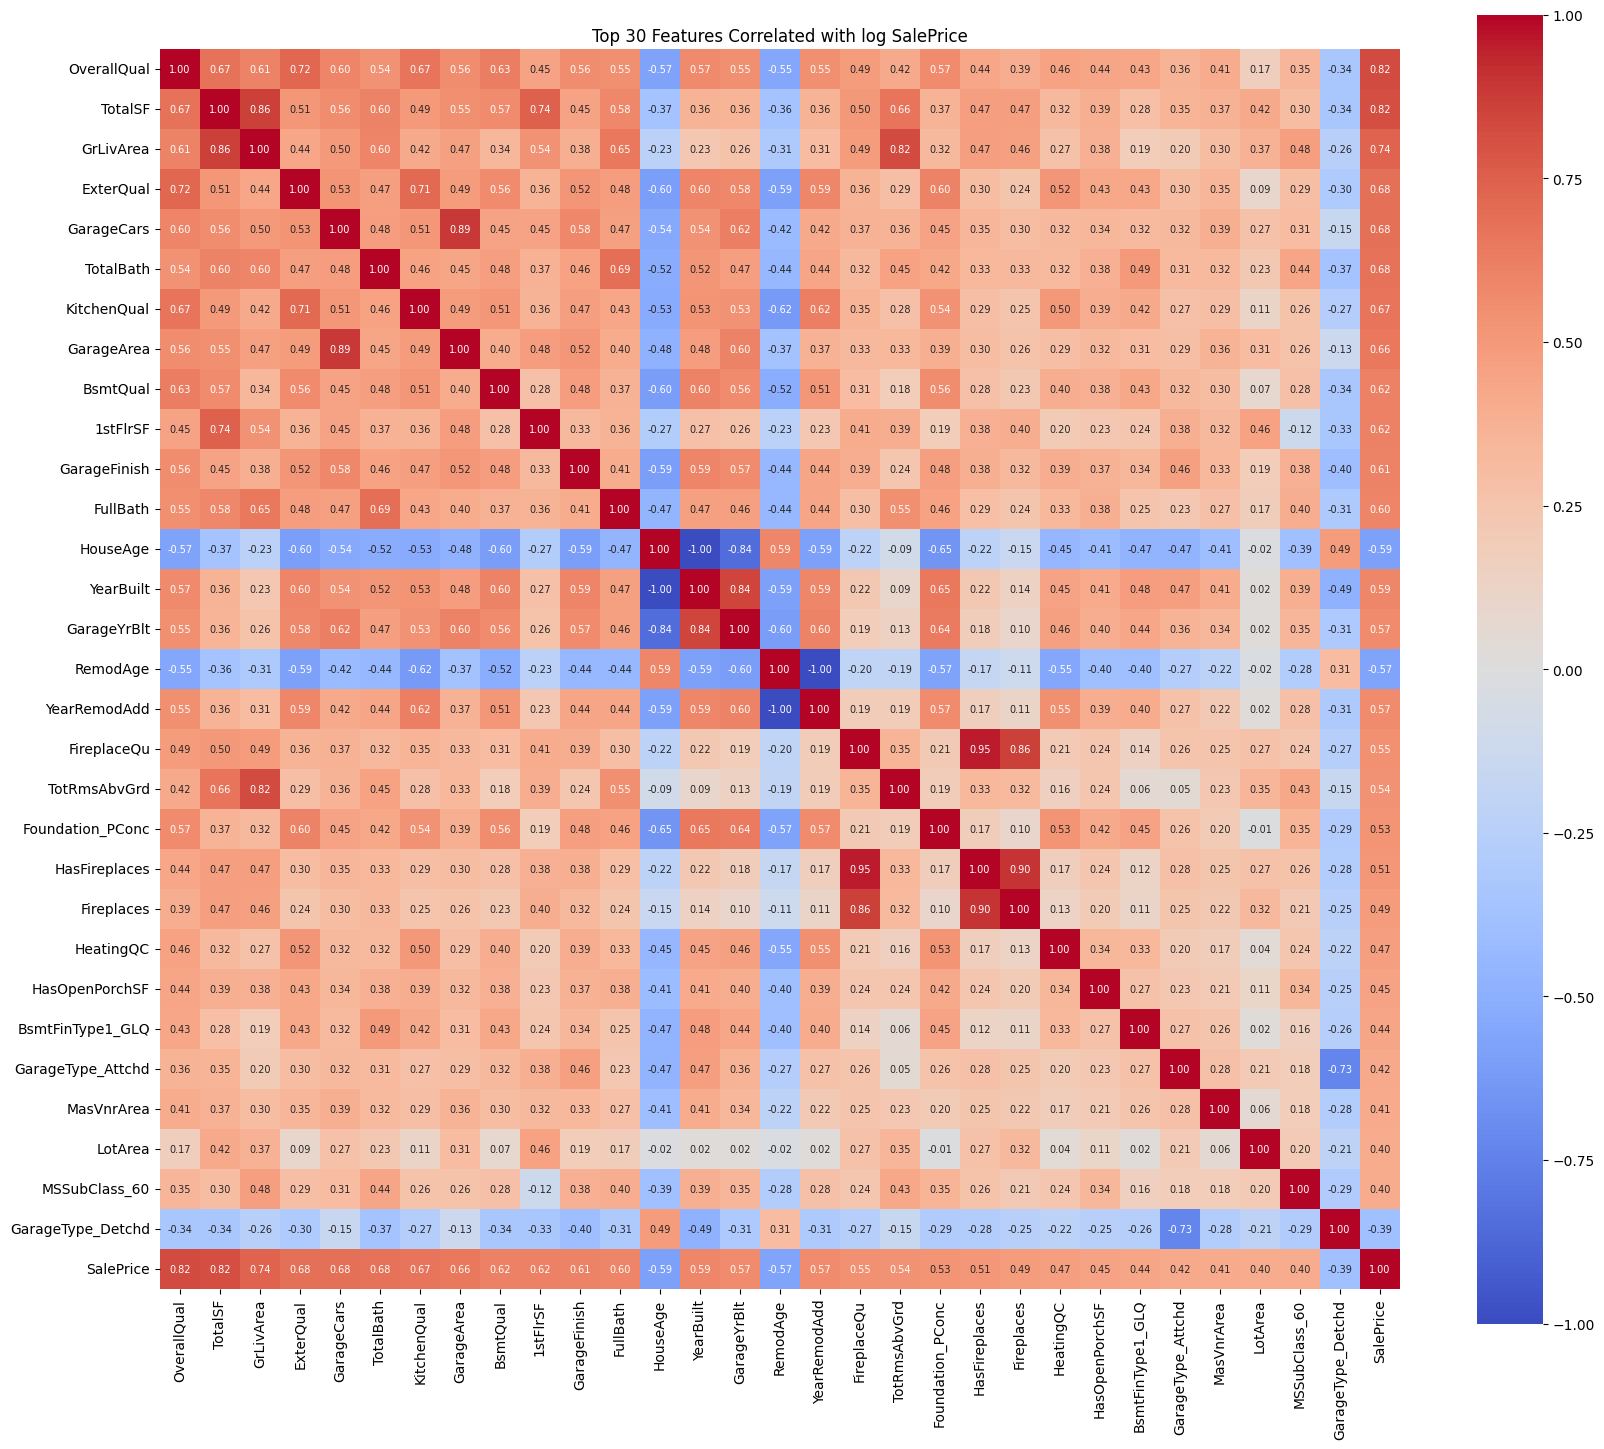

In [21]:
#2-6 Feature 간 상관관계 확인

df = X.copy()
df['SalePrice'] = y.values

corr = df.corr()['SalePrice'].drop('SalePrice')
top = corr.abs().sort_values(ascending=False).head(30).index.tolist()

plt.figure(figsize=(20, 17))
sb.heatmap(df[top + ['SalePrice']].corr(), annot=True, fmt='.2f',
           cmap='coolwarm', vmin=-1, vmax=1, square=True,
           annot_kws={'size': 7})
plt.title('Top 30 Features Correlated with log SalePrice')
plt.show()

In [22]:
#4 Modeling
#4-1 교차검증 설정
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_rmse(model):
    scores = -cross_val_score(model, X, y, cv=kf, scoring='neg_root_mean_squared_error')
    return scores.mean(), scores.std()

In [23]:
#4-2 베이스라인 모델
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

models = {
    # 선형 모델: 스케일링 필요
    'LinearRegression': make_pipeline(RobustScaler(), LinearRegression()),
    'Ridge':      make_pipeline(RobustScaler(), Ridge(alpha=10)),
    'Lasso':      make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)),
    'ElasticNet': make_pipeline(RobustScaler(), ElasticNet(alpha=0.0005, l1_ratio=0.9, max_iter=50000)),
    # 트리 모델: 스케일링 불필요
    'RandomForest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=1000, learning_rate=0.05,
                                                  max_depth=3, subsample=0.8, random_state=42),
    'XGBoost': XGBRegressor(learning_rate=0.02, n_estimators=2500, max_depth=3,
                            subsample=0.7, colsample_bytree=0.2, min_child_weight=3,
                            random_state=42, n_jobs=-1),
    'LightGBM': LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=8,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                              random_state=42, verbose=-1),
}

In [24]:
#4-3 교차검증 결과 비교
results = {}
for name, model in models.items():
    mean, std = cv_rmse(model)
    results[name] = {'RMSE': mean, 'Std': std}
    print(f'{name:18s} RMSE: {mean:.4f} (±{std:.4f})')

results_df = pd.DataFrame(results).T.sort_values('RMSE')
results_df

LinearRegression   RMSE: 0.1267 (±0.0100)
Ridge              RMSE: 0.1133 (±0.0086)
Lasso              RMSE: 0.1116 (±0.0073)
ElasticNet         RMSE: 0.1117 (±0.0074)
RandomForest       RMSE: 0.1356 (±0.0060)
GradientBoosting   RMSE: 0.1177 (±0.0050)
XGBoost            RMSE: 0.1113 (±0.0064)
LightGBM           RMSE: 0.1191 (±0.0084)


,RMSE,Std
XGBoost,0.111332,0.006436
Lasso,0.111607,0.007339
ElasticNet,0.111707,0.007353
Ridge,0.113312,0.008650
GradientBoosting,0.117713,0.004984
LightGBM,0.119059,0.008414
LinearRegression,0.126750,0.009994
RandomForest,0.135637,0.006033


In [25]:
#4-4 첫 제출
lasso = models['Lasso'].fit(X, y)
pred = np.expm1(lasso.predict(X_test))


In [26]:
#4-5 가설 검증: 피처 그룹별 기여도
lasso = make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000))

def pick(prefixes, exact):
    # exact: 그대로 있는 컬럼 / prefixes: 원-핫으로 펼쳐진 컬럼(예: Neighborhood_*)
    return [c for c in X.columns
            if c in exact or any(c.startswith(p + '_') for p in prefixes)]

groups = {
    '품질·상태': pick(['ExterCond', 'BsmtCond', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence',
                      'BsmtFinType1', 'BsmtFinType2', 'Functional'],
                     ['OverallQual', 'OverallCond', 'ExterQual', 'KitchenQual', 'BsmtQual',
                      'HeatingQC', 'FireplaceQu', 'GarageFinish', 'BsmtExposure']),
    '면적': pick([], ['GrLivArea', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LotArea', 'GarageArea',
                     'TotalSF', 'LotFrontage', 'BsmtFinSF1', 'BsmtUnfSF', 'MasVnrArea',
                     'TotalPorchSF', 'WoodDeckSF', 'OpenPorchSF', 'TotRmsAbvGrd', 'BedroomAbvGr',
                     'FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'TotalBath',
                     'KitchenAbvGr', 'GarageCars']),
    '연식': pick(['YrSold', 'MoSold'], ['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'HouseAge', 'RemodAge']),
    '입지': pick(['Neighborhood', 'MSZoning', 'Condition1', 'Condition2'], []),
    '시설 유무': [c for c in X.columns if c.startswith('Has')]
                 + pick(['GarageType', 'CentralAir', 'MiscFeature', 'Alley', 'PavedDrive',
                         'Heating', 'Electrical'], ['Fireplaces']),
}

base, _ = cv_rmse(lasso)
rows = []
for g, cols in groups.items():
    only = -cross_val_score(lasso, X[cols], y, cv=kf, scoring='neg_root_mean_squared_error').mean()
    drop = -cross_val_score(lasso, X.drop(columns=cols), y, cv=kf, scoring='neg_root_mean_squared_error').mean()
    rows.append({'그룹': g, '컬럼 수': len(cols), '그룹만 사용': only,
                 '그룹만 제거': drop, '제거 시 증가': drop - base})

print('전체 사용:', round(base, 4))
pd.DataFrame(rows).sort_values('제거 시 증가', ascending=False)

전체 사용: 0.1116


,그룹,컬럼 수,그룹만 사용,그룹만 제거,제거 시 증가
1,면적,23,0.170490,0.153702,0.042095
0,품질·상태,61,0.190336,0.130604,0.018996
3,입지,41,0.262968,0.119991,0.008384
4,시설 유무,43,0.265017,0.111957,0.000349
2,연식,22,0.305381,0.111956,0.000349


In [27]:
#4-6 앙상블 준비: out-of-fold 예측
from sklearn.model_selection import cross_val_predict

oof = pd.DataFrame({
    'Lasso': cross_val_predict(models['Lasso'], X, y, cv=kf),
    'XGBoost': cross_val_predict(models['XGBoost'], X, y, cv=kf),
})

def rmse(pred):
    return np.sqrt(((y.values - pred) ** 2).mean())

for name in oof.columns:
    print(f'{name:8s} {rmse(oof[name]):.4f}')

Lasso    0.1119
XGBoost  0.1115


In [28]:
#4-7 최적 비율 찾기
for w in np.arange(0, 1.01, 0.1):
    blend = w * oof['Lasso'] + (1 - w) * oof['XGBoost']
    print(f'Lasso {w:.1f} / XGBoost {1 - w:.1f}: {rmse(blend):.4f}')

Lasso 0.0 / XGBoost 1.0: 0.1115
Lasso 0.1 / XGBoost 0.9: 0.1103
Lasso 0.2 / XGBoost 0.8: 0.1093
Lasso 0.3 / XGBoost 0.7: 0.1086
Lasso 0.4 / XGBoost 0.6: 0.1082
Lasso 0.5 / XGBoost 0.5: 0.1081
Lasso 0.6 / XGBoost 0.4: 0.1083
Lasso 0.7 / XGBoost 0.3: 0.1088
Lasso 0.8 / XGBoost 0.2: 0.1095
Lasso 0.9 / XGBoost 0.1: 0.1106
Lasso 1.0 / XGBoost 0.0: 0.1119


In [29]:
#4-9 앙상블 제출 (Lasso 0.5 + XGBoost 0.5)
lasso = models['Lasso'].fit(X, y)
xgb = models['XGBoost'].fit(X, y)

pred_log = 0.5 * lasso.predict(X_test) + 0.5 * xgb.predict(X_test)
submission = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(pred_log)})
submission.to_csv('submission.csv', index=False)

print(submission[submission['Id'] == 2550])
submission.head()

        Id      SalePrice
1089  2550  745814.710735


,Id,SalePrice
0,1461,123281.501080
1,1462,159950.714168
2,1463,183202.012174
3,1464,197284.546576
4,1465,193149.878376


In [30]:
#4-12 특수 거래 규칙: 초대형 + 완공 전 거래(Partial)
orig = pd.read_csv(f'{DATA}/train.csv')
twin_log = np.log1p(orig.loc[orig['Id'].isin([524, 1299]), 'SalePrice']).mean()

special = ((test['GrLivArea'] > 4000) & (test['SaleCondition'] == 'Partial')).values
print(test.loc[special, ['Id', 'GrLivArea', 'Neighborhood', 'SaleCondition']])

pred_log[special] = twin_log   # 해당 집만 쌍둥이 평균 가격으로
submission = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(pred_log)})
submission.to_csv('submission.csv', index=False)
print(submission[submission['Id'] == 2550])

        Id  GrLivArea Neighborhood SaleCondition
1089  2550       5095      Edwards       Partial
        Id     SalePrice
1089  2550  171930.22099


In [31]:
#5 모델 업그레이드
#5-1 반복 교차검증 + 비교 함수
from sklearn.model_selection import RepeatedKFold

rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)

def cv_scores(model, X_=None):
    X_ = X if X_ is None else X_
    return -cross_val_score(model, X_, y, cv=rkf, scoring='neg_root_mean_squared_error')

def compare(model, X_base, X_new):
    base = cv_scores(model, X_base)
    new = cv_scores(model, X_new)
    diff = new - base
    print(f'기존 {base.mean():.4f} → 변경 {new.mean():.4f}  (차이 {diff.mean():+.4f})')
    print(f'15번 중 {(diff < 0).sum()}번 좋아짐')
    return diff


In [32]:
#5-2 반복 교차검증 기준점
lasso_base = make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000))

for name, m in [('Lasso', lasso_base), ('XGBoost', models['XGBoost'])]:
    s = cv_scores(m)
    print(f'{name:8s} 평균 {s.mean():.4f} (±{s.std():.4f}, 15번)')

Lasso    평균 0.1117 (±0.0060, 15번)
XGBoost  평균 0.1115 (±0.0055, 15번)


In [33]:
#5-3 잔차 분석: 어떤 집을 크게 틀리나
from sklearn.model_selection import cross_val_predict

p_lasso = cross_val_predict(models['Lasso'], X, y, cv=kf)
p_xgb = cross_val_predict(models['XGBoost'], X, y, cv=kf)
pred = 0.5 * p_lasso + 0.5 * p_xgb

res = train[['Id', 'SalePrice', 'SaleCondition', 'SaleType', 'MSZoning',
             'Neighborhood', 'OverallQual', 'GrLivArea', 'YearBuilt']].copy()
res['pred'] = np.expm1(pred).round()
res['res'] = y.values - pred   # +: 실제가 더 비쌈 / -: 모델이 비싸게 예측
res.reindex(res['res'].abs().sort_values(ascending=False).index).head(15)

,Id,SalePrice,SaleCondition,SaleType,MSZoning,Neighborhood,OverallQual,GrLivArea,YearBuilt,pred,res
631,633,82500,Family,WD,RL,NWAmes,7,1411,1977,176191.0,-0.758765
30,31,40000,Normal,WD,C (all),IDOTRR,4,1317,1920,80417.0,-0.698333
1322,1325,147000,Partial,New,RL,Somerst,8,1795,2006,290218.0,-0.680197
462,463,62383,Normal,WD,RL,Sawyer,5,864,1965,120189.0,-0.655768
967,969,37900,Abnorml,WD,RM,OldTown,3,968,1910,67152.0,-0.571997
495,496,34900,Abnorml,WD,C (all),IDOTRR,4,720,1920,61422.0,-0.565269
88,89,85000,Abnorml,ConLD,C (all),IDOTRR,3,1526,1915,48480.0,0.561484
587,589,143000,Partial,WD,RL,ClearCr,5,1473,1968,249241.0,-0.555573
410,411,60000,Abnorml,COD,RL,Edwards,5,1276,1958,99877.0,-0.509588
969,971,135000,Abnorml,WD,RL,NAmes,4,1192,1949,81406.0,0.505817


In [34]:
#5-4 그룹별 잔차: 치우침(평균) vs 흩어짐(RMSE)
for c in ['SaleCondition', 'MSZoning']:
    g = res.groupby(c)['res'].agg(n='size', 평균='mean', RMSE=lambda s: np.sqrt((s**2).mean()))
    display(g.round(3).sort_values('n', ascending=False))

,n,평균,RMSE
SaleCondition,,,
Normal,1198,0.002,0.089
Partial,123,0.006,0.137
Abnorml,101,-0.013,0.191
Family,20,-0.013,0.228
Alloca,12,-0.020,0.189
AdjLand,4,0.048,0.081


,n,평균,RMSE
MSZoning,,,
RL,1149,0.002,0.102
RM,218,-0.003,0.112
FV,65,0.010,0.079
RH,16,0.030,0.141
C (all),10,-0.131,0.395


In [35]:
#5-5 Lasso 계수: 모델이 무엇을 중요하게 봤나
lasso_fit = make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)).fit(X, y)
coef = pd.Series(lasso_fit[-1].coef_, index=X.columns)

print('사용한 피처:', (coef != 0).sum(), '/', len(coef))
print('\n[집값을 올리는 피처]');  print(coef.sort_values(ascending=False).head(10).round(3))
print('\n[집값을 내리는 피처]');  print(coef.sort_values().head(10).round(3))

사용한 피처: 109 / 302

[집값을 올리는 피처]
TotalSF                 0.128
OverallQual             0.104
Neighborhood_Crawfor    0.101
Neighborhood_StoneBr    0.088
Functional_Typ          0.074
2ndFlrSF                0.067
Exterior1st_BrkFace     0.060
Neighborhood_NridgHt    0.058
Neighborhood_BrkSide    0.058
1stFlrSF                0.051
dtype: float64

[집값을 내리는 피처]
MSZoning_C (all)        -0.283
HouseAge                -0.060
KitchenAbvGr            -0.060
SaleCondition_Abnorml   -0.040
CentralAir_N            -0.030
MSZoning_RM             -0.028
Neighborhood_Edwards    -0.027
GarageCond_Fa           -0.027
SaleType_WD             -0.027
MSSubClass_30           -0.020
dtype: float64


In [36]:
#5-6 피처 실험 (Lasso, 반복 교차검증으로 짝지어 비교)
# (1) ScreenPorch, EnclosedPorch 원래 값 다시 추가
raw = pd.concat([train.drop(columns=['SalePrice']), test]).reset_index(drop=True)
X_porch = X.copy()
for c in ['ScreenPorch', 'EnclosedPorch']:
    X_porch[c] = np.log1p(raw[c].fillna(0).values[:n_train])
print('[현관 원래 값 유지]');  compare(lasso_base, X, X_porch)

# (2) 중복 피처 제거
X_drop = X.drop(columns=['YearBuilt', 'YearRemodAdd', 'HasFireplaces'])
print('\n[중복 피처 제거]');  compare(lasso_base, X, X_drop)

[현관 원래 값 유지]
기존 0.1117 → 변경 0.1116  (차이 -0.0001)
15번 중 11번 좋아짐

[중복 피처 제거]
기존 0.1117 → 변경 0.1117  (차이 -0.0000)
15번 중 10번 좋아짐


array([-6.29661326e-05,  7.91334287e-06, -4.77579934e-07, -9.75422265e-05,
        5.45638084e-06, -4.88181271e-06, -7.91667882e-06, -3.22929331e-04,
       -8.14208967e-07,  8.66940235e-06, -1.10560905e-05, -3.32715348e-05,
       -5.31531289e-06,  3.57672617e-06,  5.39590359e-06])

In [37]:
import time
print(X.shape, X_porch.shape)
print(X.dtypes.value_counts())

t = time.time()
s = cv_scores(lasso_base)
print(f'Lasso 15번: {s.mean():.4f}, {time.time() - t:.1f}초')

(1458, 302) (1458, 304)
float64    302
Name: count, dtype: int64
Lasso 15번: 0.1117, 1.7초


In [38]:
#5-7 Optuna로 LightGBM 튜닝
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = dict(
        n_estimators      = trial.suggest_int('n_estimators', 500, 3000, step=250),
        learning_rate     = trial.suggest_float('learning_rate', 0.005, 0.05, log=True),
        num_leaves        = trial.suggest_int('num_leaves', 4, 32),
        min_child_samples = trial.suggest_int('min_child_samples', 5, 50),
        subsample         = trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.1, 0.6),
        reg_lambda        = trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    )
    model = LGBMRegressor(subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1, **params)
    return cv_rmse(model)[0]
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))

In [39]:
#5-8 모델 4개의 out-of-fold 예측
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_predict, KFold
from lightgbm import LGBMRegressor

# 5-7 Optuna가 찾은 설정 (seed=42 고정이라 다시 돌려도 동일)
lgbm_best = {'n_estimators': 2250, 'learning_rate': 0.009298456523634235, 'num_leaves': 21,
             'min_child_samples': 6, 'subsample': 0.6503535851137419,
             'colsample_bytree': 0.5157533506415475, 'reg_lambda': 0.0019471084472572776}

lgbm_tuned = LGBMRegressor(subsample_freq=1, random_state=42, verbose=-1, n_jobs=-1, **lgbm_best)
svr = make_pipeline(RobustScaler(), SVR(C=20, epsilon=0.008, gamma=0.0003))

base_models = {'Lasso': models['Lasso'], 'XGBoost': models['XGBoost'],
               'LightGBM': lgbm_tuned, 'SVR': svr}
oof = pd.DataFrame({n: cross_val_predict(m, X, y, cv=kf) for n, m in base_models.items()})

for n in oof.columns:
    print(f'{n:9s} {rmse(oof[n]):.4f}')
oof.sub(y.values, axis=0).corr().round(3)   # 오차 상관: 낮을수록 다르게 틀림

Lasso     0.1119
XGBoost   0.1115
LightGBM  0.1142
SVR       0.1123


,Lasso,XGBoost,LightGBM,SVR
Lasso,1.000,0.875,0.849,0.940
XGBoost,0.875,1.000,0.959,0.864
LightGBM,0.849,0.959,1.000,0.856
SVR,0.940,0.864,0.856,1.000


In [40]:
#5-9 스태킹: 비율을 학습하고, 정직하게 채점
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

meta = LinearRegression(positive=True)            # 가중치를 0 이상으로 제한
kf2 = KFold(n_splits=5, shuffle=True, random_state=7)   # 비율 학습용 분할 (모델 학습과 다른 분할)

combos = [['Lasso', 'XGBoost'],
          ['Lasso', 'XGBoost', 'SVR'],
          ['Lasso', 'XGBoost', 'LightGBM', 'SVR']]

for cols in combos:
    p = cross_val_predict(meta, oof[cols], y, cv=kf2)   # 정직한 점수: 비율 학습과 채점 분리
    w = meta.fit(oof[cols], y).coef_                    # 전체로 학습한 최종 가중치
    print(f'{" + ".join(cols):35s} 스태킹 {rmse(p):.4f}   가중치 {dict(zip(cols, w.round(2)))}')

Lasso + XGBoost                     스태킹 0.1083   가중치 {'Lasso': np.float64(0.49), 'XGBoost': np.float64(0.52)}
Lasso + XGBoost + SVR               스태킹 0.1077   가중치 {'Lasso': np.float64(0.23), 'XGBoost': np.float64(0.46), 'SVR': np.float64(0.33)}
Lasso + XGBoost + LightGBM + SVR    스태킹 0.1078   가중치 {'Lasso': np.float64(0.23), 'XGBoost': np.float64(0.38), 'LightGBM': np.float64(0.09), 'SVR': np.float64(0.31)}


In [41]:
#5-10 최종 제출: Lasso + XGBoost + SVR 스태킹 + Id 2550 규칙
cols = ['Lasso', 'XGBoost', 'SVR']
meta.fit(oof[cols], y)   # 최종 가중치 학습

# 각 모델을 train 전체로 다시 학습해서 test 예측
test_preds = pd.DataFrame({n: base_models[n].fit(X, y).predict(X_test) for n in cols})
pred_log = meta.predict(test_preds)

# Id 2550 특수 거래 규칙 (4-12와 동일)
orig = pd.read_csv(f'{DATA}/train.csv')
twin_log = np.log1p(orig.loc[orig['Id'].isin([524, 1299]), 'SalePrice']).mean()
special = ((test['GrLivArea'] > 4000) & (test['SaleCondition'] == 'Partial')).values
pred_log[special] = twin_log

submission = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(pred_log)})
submission.to_csv('submission.csv', index=False)

print(submission[submission['Id'] == 2550])
submission.head()

        Id     SalePrice
1089  2550  171930.22099


,Id,SalePrice
0,1461,122678.066288
1,1462,161122.002638
2,1463,186517.009078
3,1464,198525.224165
4,1465,191840.508202


In [42]:
#5-11 상호작용 피처 (선형 모델용)
def add_interactions(df):
    df = df.copy()
    df['Qual_SF'] = df['OverallQual'] * df['TotalSF']      # 품질 × 총면적
    df['Qual_Liv'] = df['OverallQual'] * df['GrLivArea']   # 품질 × 지상면적
    df['Qual2'] = df['OverallQual'] ** 2                   # 품질이 오를수록 가속
    df['SF2'] = df['TotalSF'] ** 2                         # 면적이 커질수록 가속
    return df

X_int, X_test_int = add_interactions(X), add_interactions(X_test)

print('[Lasso]'); _ = compare(lasso_base, X, X_int)
print('[SVR]');   _ = compare(svr, X, X_int)

[Lasso]
기존 0.1117 → 변경 0.1106  (차이 -0.0011)
15번 중 15번 좋아짐
[SVR]
기존 0.1116 → 변경 0.1110  (차이 -0.0006)
15번 중 12번 좋아짐


In [43]:
#5-12 스태킹 v2: Lasso·SVR은 상호작용 피처, XGBoost는 원래 피처
oof2 = pd.DataFrame({
    'Lasso': cross_val_predict(models['Lasso'], X_int, y, cv=kf),
    'XGBoost': oof['XGBoost'],          # 5-8에서 구한 것 재사용 (다시 안 돌려도 됨)
    'SVR': cross_val_predict(svr, X_int, y, cv=kf),
})
p = cross_val_predict(meta, oof2, y, cv=kf2)
meta.fit(oof2, y)
print(f'스태킹 v2 {rmse(p):.4f}', dict(zip(oof2.columns, meta.coef_.round(2))))

스태킹 v2 0.1074 {'Lasso': np.float64(0.29), 'XGBoost': np.float64(0.42), 'SVR': np.float64(0.3)}


In [44]:
#5-13 제출 v2: 상호작용 피처 + 스태킹 + Id 2550 규칙
feats = {'Lasso': (X_int, X_test_int),   # 선형 모델: 상호작용 피처
         'XGBoost': (X, X_test),         # 트리 모델: 원래 피처
         'SVR': (X_int, X_test_int)}

meta.fit(oof2, y)   # 5-12의 OOF로 최종 가중치 학습
test_preds = pd.DataFrame({n: base_models[n].fit(feats[n][0], y).predict(feats[n][1])
                           for n in oof2.columns})
pred_log = meta.predict(test_preds)
pred_log[special] = twin_log   # 5-10에서 만든 Id 2550 규칙

submission = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(pred_log)})
submission.to_csv('submission.csv', index=False)

print('가중치:', dict(zip(oof2.columns, meta.coef_.round(2))))
print(submission[submission['Id'] == 2550])
submission.head()

가중치: {'Lasso': np.float64(0.29), 'XGBoost': np.float64(0.42), 'SVR': np.float64(0.3)}
        Id     SalePrice
1089  2550  171930.22099


,Id,SalePrice
0,1461,122320.775306
1,1462,160886.562354
2,1463,185971.571581
3,1464,198653.026009
4,1465,192684.849016


In [45]:
#5-14 v3: 곱셈 항만 (제곱 항 제외)
def add_interactions_v3(df):
    df = df.copy()
    df['Qual_SF'] = df['OverallQual'] * df['TotalSF']      # 품질 × 총면적
    df['Qual_Liv'] = df['OverallQual'] * df['GrLivArea']   # 품질 × 지상면적
    return df

X_v3, X_test_v3 = add_interactions_v3(X), add_interactions_v3(X_test)

print('[Lasso]'); _ = compare(lasso_base, X, X_v3)
print('[SVR]');   _ = compare(svr, X, X_v3)

[Lasso]
기존 0.1117 → 변경 0.1114  (차이 -0.0004)
15번 중 15번 좋아짐
[SVR]
기존 0.1116 → 변경 0.1112  (차이 -0.0004)
15번 중 13번 좋아짐


In [46]:
#5-15 v3 스태킹 + 제출
oof3 = pd.DataFrame({
    'Lasso': cross_val_predict(models['Lasso'], X_v3, y, cv=kf),
    'XGBoost': oof['XGBoost'],                 # 재사용
    'SVR': cross_val_predict(svr, X_v3, y, cv=kf),
})
p = cross_val_predict(meta, oof3, y, cv=kf2)
meta.fit(oof3, y)
print(f'스태킹 v3 {rmse(p):.4f}', dict(zip(oof3.columns, meta.coef_.round(2))))

feats = {'Lasso': (X_v3, X_test_v3), 'XGBoost': (X, X_test), 'SVR': (X_v3, X_test_v3)}
test_preds = pd.DataFrame({n: base_models[n].fit(feats[n][0], y).predict(feats[n][1])
                           for n in oof3.columns})
pred_log = meta.predict(test_preds)
pred_log[special] = twin_log

submission = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(pred_log)})
submission.to_csv('submission.csv', index=False)
submission.head()

스태킹 v3 0.1076 {'Lasso': np.float64(0.24), 'XGBoost': np.float64(0.45), 'SVR': np.float64(0.33)}


,Id,SalePrice
0,1461,122469.771164
1,1462,161163.066131
2,1463,185959.585653
3,1464,198434.832890
4,1465,191924.589562


In [47]:
#5-16 가설 1: 비정상 거래의 학습 가중치 낮추기
abn = (train['SaleCondition'] != 'Normal').values
print('비정상 거래:', abn.sum(), '채 /', len(abn))

def cv_w(model, key, w):
    return -cross_val_score(model, X, y, cv=rkf, scoring='neg_root_mean_squared_error',
                            params={key: w})

for name, m, key in [('Lasso', lasso_base, 'lasso__sample_weight'),
                     ('SVR', svr, 'svr__sample_weight')]:
    base = cv_scores(m)
    for wv in [0.7, 0.5, 0.3]:
        s = cv_w(m, key, np.where(abn, wv, 1.0))
        d = s - base
        print(f'{name:5s} 가중치 {wv}: {base.mean():.4f} → {s.mean():.4f} '
              f'({d.mean():+.4f}), 15번 중 {(d < 0).sum()}번 개선')

비정상 거래: 260 채 / 1458
Lasso 가중치 0.7: 0.1117 → 0.1112 (-0.0006), 15번 중 13번 개선
Lasso 가중치 0.5: 0.1117 → 0.1110 (-0.0007), 15번 중 13번 개선
Lasso 가중치 0.3: 0.1117 → 0.1111 (-0.0006), 15번 중 10번 개선
SVR   가중치 0.7: 0.1116 → 0.1114 (-0.0001), 15번 중 8번 개선
SVR   가중치 0.5: 0.1116 → 0.1115 (-0.0000), 15번 중 8번 개선
SVR   가중치 0.3: 0.1116 → 0.1118 (+0.0003), 15번 중 5번 개선


In [48]:
#5-17 가설 2: 오래된 집 × 리모델링
raw = pd.concat([train.drop(columns=['SalePrice']), test]).reset_index(drop=True)
yb, yr = raw['YearBuilt'].values, raw['YearRemodAdd'].values
ys = raw['YrSold'].astype(int).values
old = ((ys - yb) > 60).astype(int)
remod = ((yr != yb) & ~((yb < 1950) & (yr == 1950))).astype(int)   # 1950은 잘린 값 → 리모델링 불명

A = pd.concat([X, X_test]).reset_index(drop=True)
A['Remodeled'] = remod
A['Old'] = old
A['Old_Remod'] = old * remod                                  # 오래됐는데 리모델링함
A['Old_Cond'] = old * raw['OverallCond'].values               # 오래된 집의 상태 등급
A['Old_RemodAge'] = old * np.clip(ys - yr, 0, None)           # 오래된 집의 리모델링 경과 연수
X_h2 = A[:n_train]

w = {'lasso__sample_weight': np.where(abn, 0.5, 1.0)}   # 가설 1 반영한 Lasso가 기준
base = -cross_val_score(lasso_base, X, y, cv=rkf, scoring='neg_root_mean_squared_error', params=w)
new = -cross_val_score(lasso_base, X_h2, y, cv=rkf, scoring='neg_root_mean_squared_error', params=w)
d = new - base
print(f'{base.mean():.4f} → {new.mean():.4f} ({d.mean():+.4f}), 15번 중 {(d < 0).sum()}번 개선')

0.1110 → 0.1109 (-0.0001), 15번 중 10번 개선


In [49]:
#5-18 가설 3: 품질 구간별로 스태킹 가중치를 따로 학습
oof_h = pd.DataFrame({'Lasso': cross_val_predict(models['Lasso'], X, y, cv=kf, params=w),
                      'XGBoost': oof['XGBoost'], 'SVR': oof['SVR']})
q = train['OverallQual'].values
seg = np.select([q <= 4, q <= 7], ['low', 'mid'], 'high')   # 1~4 / 5~7 / 8~10

def seg_stack(seed):
    k = KFold(n_splits=5, shuffle=True, random_state=seed)
    g, s = np.zeros(len(y)), np.zeros(len(y))
    for tr, va in k.split(oof_h):
        g[va] = LinearRegression(positive=True).fit(oof_h.iloc[tr], y.iloc[tr]).predict(oof_h.iloc[va])
        for name in ['low', 'mid', 'high']:
            t, v = tr[seg[tr] == name], va[seg[va] == name]
            s[v] = LinearRegression(positive=True).fit(oof_h.iloc[t], y.iloc[t]).predict(oof_h.iloc[v])
    return rmse(g), rmse(s)

for seed in [7, 1, 2, 3, 4, 5]:
    g, s = seg_stack(seed)
    print(f'seed {seed}: 전체 {g:.4f}  구간별 {s:.4f}  → {"구간별 승" if s < g else "전체 승"}')

seed 7: 전체 0.1075  구간별 0.1068  → 구간별 승
seed 1: 전체 0.1077  구간별 0.1074  → 구간별 승
seed 2: 전체 0.1079  구간별 0.1080  → 전체 승
seed 3: 전체 0.1076  구간별 0.1073  → 구간별 승
seed 4: 전체 0.1078  구간별 0.1078  → 구간별 승
seed 5: 전체 0.1076  구간별 0.1079  → 전체 승


In [50]:
#5-19 최종 제출: Lasso만 비정상 거래 가중치 0.5
oof_f = oof_h[['Lasso', 'XGBoost', 'SVR']]          # 5-18에서 만든 가중치 Lasso의 OOF
p = cross_val_predict(meta, oof_f, y, cv=kf2)
meta.fit(oof_f, y)
print(f'스태킹 {rmse(p):.4f}', dict(zip(oof_f.columns, meta.coef_.round(2))))

w_full = np.where(abn, 0.5, 1.0)
test_preds = pd.DataFrame({
    'Lasso': models['Lasso'].fit(X, y, lasso__sample_weight=w_full).predict(X_test),
    'XGBoost': base_models['XGBoost'].fit(X, y).predict(X_test),
    'SVR': base_models['SVR'].fit(X, y).predict(X_test),
})
pred_log = meta.predict(test_preds)
pred_log[special] = twin_log                          # Id 2550 규칙

submission = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(pred_log)})
submission.to_csv('submission.csv', index=False)
submission.head()

스태킹 0.1075 {'Lasso': np.float64(0.29), 'XGBoost': np.float64(0.45), 'SVR': np.float64(0.28)}


,Id,SalePrice
0,1461,122726.762816
1,1462,160930.356791
2,1463,186014.420868
3,1464,198812.145964
4,1465,191861.276602


In [51]:
#5-20 Huber 계열: 큰 오차를 자동으로 덜 세는 모델
from sklearn.linear_model import HuberRegressor

huber_models = {
    'HuberLinear': make_pipeline(RobustScaler(), HuberRegressor(epsilon=1.35, alpha=30, max_iter=3000)),
    'GBR_huber': GradientBoostingRegressor(n_estimators=2000, learning_rate=0.02, max_depth=4,
                                          max_features='sqrt', min_samples_leaf=15,
                                          loss='huber', subsample=0.8, random_state=42),
    'XGB_pseudohuber': XGBRegressor(objective='reg:pseudohubererror', huber_slope=0.1,
                                    learning_rate=0.02, n_estimators=2500, max_depth=3,
                                    subsample=0.7, colsample_bytree=0.2, min_child_weight=3,
                                    base_score=float(y.mean()), random_state=42, n_jobs=-1),
}

base_cols = ['Lasso', 'XGBoost', 'SVR']
for name, m in huber_models.items():
    oof[name] = cross_val_predict(m, X, y, cv=kf)
    corr = oof[[name] + base_cols].sub(y.values, axis=0).corr()[name][base_cols]
    cols = base_cols + [name]
    p = cross_val_predict(meta, oof[cols], y, cv=kf2)
    w = meta.fit(oof[cols], y).coef_
    print(f'{name:16s} 단독 {rmse(oof[name]):.4f} | 오차상관 {corr.round(3).tolist()} '
          f'| 스태킹 {rmse(p):.4f} (가중치 {w[-1]:.2f})')

HuberLinear      단독 0.1133 | 오차상관 [0.948, 0.851, 0.975] | 스태킹 0.1078 (가중치 0.05)
GBR_huber        단독 0.1132 | 오차상관 [0.859, 0.941, 0.889] | 스태킹 0.1078 (가중치 0.15)
XGB_pseudohuber  단독 0.1155 | 오차상관 [0.85, 0.945, 0.873] | 스태킹 0.1077 (가중치 0.00)


In [52]:
#5-21 kNN: 비교 사례 방식 (전체 vs 같은 동네)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer

core = ['TotalSF', 'OverallQual', 'GrLivArea', 'HouseAge', 'RemodAge', 'GarageCars',
        'TotalBath', 'LotArea', 'ExterQual', 'KitchenQual', 'BsmtQual']
nbhd = [c for c in X.columns if c.startswith('Neighborhood_')]

def make_knn(k, same_nbhd=True):
    if same_nbhd:   # 동네 컬럼 × 100 → 같은 동네 안에서만 이웃을 찾음
        ct = ColumnTransformer([('num', StandardScaler(), core),
                                ('nb', FunctionTransformer(lambda a: a * 100), nbhd)])
        return make_pipeline(ct, KNeighborsRegressor(n_neighbors=k, weights='distance')), core + nbhd
    return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k, weights='distance')), core

base_cols = ['Lasso', 'XGBoost', 'SVR']
for same in [False, True]:
    for k in [3, 5, 8]:
        m, cols = make_knn(k, same)
        name = f'kNN{k}_{"동네" if same else "전체"}'
        oof[name] = cross_val_predict(m, X[cols], y, cv=kf)
        corr = oof[[name] + base_cols].sub(y.values, axis=0).corr()[name][base_cols]
        p = cross_val_predict(meta, oof[base_cols + [name]], y, cv=kf2)
        print(f'{name:10s} 단독 {rmse(oof[name]):.4f} | 오차상관 {corr.round(2).tolist()} | 스태킹 {rmse(p):.4f}')

kNN3_전체    단독 0.1593 | 오차상관 [0.64, 0.67, 0.67] | 스태킹 0.1077
kNN5_전체    단독 0.1512 | 오차상관 [0.67, 0.7, 0.7] | 스태킹 0.1078
kNN8_전체    단독 0.1492 | 오차상관 [0.69, 0.72, 0.72] | 스태킹 0.1078
kNN3_동네    단독 0.1595 | 오차상관 [0.55, 0.58, 0.59] | 스태킹 0.1071
kNN5_동네    단독 0.1589 | 오차상관 [0.59, 0.6, 0.62] | 스태킹 0.1073
kNN8_동네    단독 0.1639 | 오차상관 [0.59, 0.6, 0.62] | 스태킹 0.1076


In [53]:
#5-22 우연인지 확인: 스태킹 분할을 6가지로 바꿔서 비교
k_name = 'kNN3_동네'
for seed in [7, 1, 2, 3, 4, 5]:
    k2 = KFold(n_splits=5, shuffle=True, random_state=seed)
    g = rmse(cross_val_predict(meta, oof[base_cols], y, cv=k2))
    s = rmse(cross_val_predict(meta, oof[base_cols + [k_name]], y, cv=k2))
    print(f'seed {seed}: 기존 {g:.4f} → kNN 추가 {s:.4f} ({s - g:+.5f})')

seed 7: 기존 0.1077 → kNN 추가 0.1071 (-0.00061)
seed 1: 기존 0.1079 → kNN 추가 0.1075 (-0.00037)
seed 2: 기존 0.1081 → kNN 추가 0.1073 (-0.00072)
seed 3: 기존 0.1079 → kNN 추가 0.1072 (-0.00062)
seed 4: 기존 0.1079 → kNN 추가 0.1073 (-0.00066)
seed 5: 기존 0.1077 → kNN 추가 0.1073 (-0.00047)


In [54]:
#5-23 제출: Lasso + XGBoost + SVR + 같은 동네 kNN(k=3) + Id 2550 규칙
knn3, knn_cols = make_knn(3, same_nbhd=True)
cols = ['Lasso', 'XGBoost', 'SVR', 'kNN3_동네']

p = cross_val_predict(meta, oof[cols], y, cv=kf2)
meta.fit(oof[cols], y)
print(f'스태킹 {rmse(p):.4f}', dict(zip(cols, meta.coef_.round(2))))

test_preds = pd.DataFrame({
    'Lasso': base_models['Lasso'].fit(X, y).predict(X_test),
    'XGBoost': base_models['XGBoost'].fit(X, y).predict(X_test),
    'SVR': base_models['SVR'].fit(X, y).predict(X_test),
    'kNN3_동네': knn3.fit(X[knn_cols], y).predict(X_test[knn_cols]),
})
pred_log = meta.predict(test_preds)
pred_log[special] = twin_log

submission = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(pred_log)})
submission.to_csv('submission.csv', index=False)
submission.head()

스태킹 0.1071 {'Lasso': np.float64(0.23), 'XGBoost': np.float64(0.41), 'SVR': np.float64(0.28), 'kNN3_동네': np.float64(0.1)}


,Id,SalePrice
0,1461,121895.789946
1,1462,157565.490859
2,1463,186137.639780
3,1464,196774.608396
4,1465,192131.478480


In [55]:
#6-0 스택 재료 다시 만들기 (세션이 재시작됐을 때)
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer

kf2 = KFold(n_splits=5, shuffle=True, random_state=7)       # 스태킹 비율 학습용 분할
meta = LinearRegression(positive=True)                       # 스태킹 모델
def rmse(pred):
    return np.sqrt(((y.values - pred) ** 2).mean())

# 가설 1: 비정상 거래 가중치 0.5
abn = (train['SaleCondition'] != 'Normal').values
w = np.where(abn, 0.5, 1.0)

# SVR
svr = make_pipeline(RobustScaler(), SVR(C=20, epsilon=0.008, gamma=0.0003))
base_models = {'XGBoost': models['XGBoost'], 'SVR': svr}

# 같은 동네 kNN
core = ['TotalSF', 'OverallQual', 'GrLivArea', 'HouseAge', 'RemodAge', 'GarageCars',
        'TotalBath', 'LotArea', 'ExterQual', 'KitchenQual', 'BsmtQual']
nbhd = [c for c in X.columns if c.startswith('Neighborhood_')]
def make_knn(k, same_nbhd=True):
    if same_nbhd:
        ct = ColumnTransformer([('num', StandardScaler(), core),
                                ('nb', FunctionTransformer(lambda a: a * 100), nbhd)])
        return make_pipeline(ct, KNeighborsRegressor(n_neighbors=k, weights='distance')), core + nbhd
    return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k, weights='distance')), core
knn3, knn_cols = make_knn(3, same_nbhd=True)

# 네 모델의 OOF 예측 (같은 분할 kf)
oof_final = pd.DataFrame({
    'Lasso_w': cross_val_predict(models['Lasso'], X, y, cv=kf, params={'lasso__sample_weight': w}),
    'XGBoost': cross_val_predict(models['XGBoost'], X, y, cv=kf),
    'SVR': cross_val_predict(svr, X, y, cv=kf),
    'kNN3_동네': cross_val_predict(knn3, X[knn_cols], y, cv=kf),
})
for c in oof_final.columns:
    print(f'{c:10s} {rmse(oof_final[c]):.4f}')

Lasso_w    0.1113
XGBoost    0.1115
SVR        0.1123
kNN3_동네    0.1595


In [56]:
#6-1 구조 모델 v2 / v3 정의 (extras=True면 v3: 부대시설 추가)
from scipy.optimize import least_squares

qmap = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
def prep_struct(d):
    d = d.copy()
    for c in ['TotalBsmtSF', 'GarageArea', 'BsmtFullBath', 'BsmtHalfBath']:
        d[c] = d[c].fillna(0)
    ys = d['YrSold'].astype(int)
    d['age'] = (ys - d['YearBuilt']).clip(lower=0)
    d['remod_age'] = (ys - d['YearRemodAdd']).clip(lower=0)
    d['MSZoning'] = d['MSZoning'].fillna('RL')
    d['KQ'] = d['KitchenQual'].map(qmap).fillna(3)
    d['bath'] = d['FullBath'] + 0.5 * d['HalfBath'] + d['BsmtFullBath'] + 0.5 * d['BsmtHalfBath']
    d['porch'] = d[['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', 'ScreenPorch', '3SsnPorch']].sum(axis=1)
    d['air'] = (d['CentralAir'] == 'Y').astype(float)
    return d

S_train, S_test = prep_struct(train), prep_struct(test)
nbs = sorted(S_train['Neighborhood'].unique())
nb_idx = {n: i for i, n in enumerate(nbs)}
K = len(nbs)
SALE = ['Abnorml', 'Family', 'Alloca', 'Partial', 'AdjLand']
ZONE = ['C (all)', 'RM', 'RH', 'FV']

def predict_struct(th, d, extras):
    land, bld = th[:K], th[K:2*K]; o = 2 * K
    b_lot, w_bs, w_gar, g_q, g_c, d_age, d_rem = th[o:o+7]; o += 7
    s_mult = th[o:o+len(SALE)]; o += len(SALE)
    z_mult = th[o:o+len(ZONE)]; o += len(ZONE)
    i = d['Neighborhood'].map(nb_idx).values
    land_val = np.exp(land[i]) * (d['LotArea'].values / 10000) ** b_lot
    area = d['GrLivArea'].values + w_bs * d['TotalBsmtSF'].values + w_gar * d['GarageArea'].values
    quality = np.exp(g_q * (d['OverallQual'].values - 5) + g_c * (d['OverallCond'].values - 5))
    depreciation = np.exp(-d_age * d['age'].values - d_rem * d['remod_age'].values)
    total = land_val + np.exp(bld[i]) * area * quality * depreciation / 1000
    if extras:   # v3: 주방·냉방은 배수, 욕실·벽난로·현관은 개당 금액(천 달러)
        e_bath, e_fp, e_porch, g_k, g_air = th[o:o+5]
        total = total * np.exp(g_k * (d['KQ'].values - 3) + g_air * (d['air'].values - 1)) \
              + e_bath * d['bath'].values + e_fp * d['Fireplaces'].values + e_porch * d['porch'].values / 100
    adj = sum(s_mult[j] * (d['SaleCondition'].values == c) for j, c in enumerate(SALE)) \
        + sum(z_mult[j] * (d['MSZoning'].values == c) for j, c in enumerate(ZONE))
    return np.log1p(np.clip(total, 1, None) * np.exp(adj) * 1000)

def fit_struct(d, yv, extras, lam=0.3):
    th0 = np.r_[np.full(K, np.log(30)), np.full(K, np.log(80)), 0.5, 0.4, 0.3, 0.15, 0.03, 0.005, 0.002,
                np.zeros(len(SALE) + len(ZONE))]
    if extras:
        th0 = np.r_[th0, 3, 3, 1, 0.05, 0.05]
    def residual(th):
        land, bld = th[:K], th[K:2*K]
        pen = 0.1 * np.sqrt(lam) * np.r_[land - land.mean(), bld - bld.mean()]
        return np.r_[predict_struct(th, d, extras) - yv, pen]
    return least_squares(residual, th0, max_nfev=5000).x

In [57]:
#6-2 v2, v3 교차검증 (같은 분할 kf)
for name, extras in [('구조v2', False), ('구조v3', True)]:
    oof_final[name] = 0.0
    for tr_i, va_i in kf.split(S_train):
        th = fit_struct(S_train.iloc[tr_i], y.values[tr_i], extras)
        oof_final.loc[va_i, name] = predict_struct(th, S_train.iloc[va_i], extras)
    print(f'{name} 단독: {rmse(oof_final[name]):.4f}')

구조v2 단독: 0.1219
구조v3 단독: 0.1146


In [58]:
#6-3 스택 비교: 기존 vs +v2 vs +v3 (6가지 분할)
ref = ['Lasso_w', 'XGBoost', 'SVR', 'kNN3_동네']
for seed in [7, 1, 2, 3, 4, 5]:
    k2 = KFold(n_splits=5, shuffle=True, random_state=seed)
    s = {n: rmse(cross_val_predict(meta, oof_final[c], y, cv=k2))
         for n, c in [('기존', ref), ('+v2', ref + ['구조v2']), ('+v3', ref + ['구조v3'])]}
    print(f"seed {seed}: 기존 {s['기존']:.4f} | +v2 {s['+v2']:.4f} | +v3 {s['+v3']:.4f}")

meta.fit(oof_final[ref + ['구조v3']], y)
print('v3 포함 가중치:', dict(zip(ref + ['구조v3'], meta.coef_.round(2))))

seed 7: 기존 0.1069 | +v2 0.1063 | +v3 0.1058
seed 1: 기존 0.1073 | +v2 0.1065 | +v3 0.1061
seed 2: 기존 0.1072 | +v2 0.1062 | +v3 0.1060
seed 3: 기존 0.1070 | +v2 0.1061 | +v3 0.1057
seed 4: 기존 0.1072 | +v2 0.1062 | +v3 0.1059
seed 5: 기존 0.1072 | +v2 0.1063 | +v3 0.1060
v3 포함 가중치: {'Lasso_w': np.float64(0.07), 'XGBoost': np.float64(0.33), 'SVR': np.float64(0.28), 'kNN3_동네': np.float64(0.06), '구조v3': np.float64(0.29)}


In [59]:
#6-4 v3 해석
th_v3 = fit_struct(S_train, y.values, extras=True)
o = 2 * K
names = ['대지 탄력성', '지하 비중', '차고 비중', '품질 1등급당', '상태 1등급당', '연간 감가', '리모델링 후 감가']
print(dict(zip(names, th_v3[o:o+7].round(4))))
print('거래 조건(%):', dict(zip(SALE, (np.expm1(th_v3[o+7:o+12]) * 100).round(1))))
print('용도지역(%):', dict(zip(ZONE, (np.expm1(th_v3[o+12:o+16]) * 100).round(1))))
e = th_v3[o+16:]
print(f'욕실 1개 +{e[0]*1000:,.0f}$ | 벽난로 1개 +{e[1]*1000:,.0f}$ | 현관 100sqft +{e[2]*1000:,.0f}$ '
      f'| 주방 1등급 +{np.expm1(e[3])*100:.1f}% | 냉방 없음 {np.expm1(-e[4])*100:.1f}%')

{'대지 탄력성': np.float64(0.2123), '지하 비중': np.float64(0.6464), '차고 비중': np.float64(0.7034), '품질 1등급당': np.float64(0.1049), '상태 1등급당': np.float64(0.0853), '연간 감가': np.float64(0.0049), '리모델링 후 감가': np.float64(0.0012)}
거래 조건(%): {'Abnorml': np.float64(-6.6), 'Family': np.float64(-6.5), 'Alloca': np.float64(-0.9), 'Partial': np.float64(4.2), 'AdjLand': np.float64(5.0)}
용도지역(%): {'C (all)': np.float64(-21.9), 'RM': np.float64(-3.9), 'RH': np.float64(3.8), 'FV': np.float64(4.7)}
욕실 1개 +6,440$ | 벽난로 1개 +5,495$ | 현관 100sqft +1,972$ | 주방 1등급 +3.7% | 냉방 없음 -7.7%


In [60]:
#6-5 최종 제출: 가중치 Lasso + XGBoost + SVR + kNN + 구조 모델 v3 + Id 2550 규칙
cols = ref + ['구조v3']
meta.fit(oof_final[cols], y)

w_full = np.where(abn, 0.5, 1.0)
knn3, knn_cols = make_knn(3, same_nbhd=True)
test_preds = pd.DataFrame({
    'Lasso_w': models['Lasso'].fit(X, y, lasso__sample_weight=w_full).predict(X_test),
    'XGBoost': base_models['XGBoost'].fit(X, y).predict(X_test),
    'SVR': base_models['SVR'].fit(X, y).predict(X_test),
    'kNN3_동네': knn3.fit(X[knn_cols], y).predict(X_test[knn_cols]),
    '구조v3': predict_struct(th_v3, S_test, extras=True),
})
pred_log = meta.predict(test_preds[cols])

orig = pd.read_csv(f'{DATA}/train.csv')
twin_log = np.log1p(orig.loc[orig['Id'].isin([524, 1299]), 'SalePrice']).mean()
special = ((test['GrLivArea'] > 4000) & (test['SaleCondition'] == 'Partial')).values
pred_log[special] = twin_log

submission = pd.DataFrame({'Id': test_id, 'SalePrice': np.expm1(pred_log)})
submission.to_csv('submission.csv', index=False)
submission.head()

,Id,SalePrice
0,1461,126159.103378
1,1462,159141.195191
2,1463,184320.415919
3,1464,197092.445694
4,1465,194457.030323
